# Melon ripeness detection (MRD-YOLO) — test-split validation of the released weights

**Paper:** Xuebin Jing, Yuanhao Wang, Dongxi Li, Weihua Pan. *Melon ripeness detection by an improved object detection algorithm for resource constrained environments.* Plant Methods 2024;20:127. [DOI 10.1186/s13007-024-01259-3](https://doi.org/10.1186/s13007-024-01259-3)

**Author code:** [XuebinJing/Melon-Ripeness-Detection](https://github.com/XuebinJing/Melon-Ripeness-Detection) at pinned commit `d8ae609f9a1e86be6402041b3770e856745e421d` (vendored ultralytics 8.0.184).

**Scope (one faithful example):** run the authors' released `weights/MRD.pt` through their own `Test.py` procedure — `model.val(data='dataset/melon.yaml', split='test', batch=1)` — on the 300-image melon test split shipped in the repository, then compare with the paper's reported test-set values (P 95.0 %, R 94.1 %, mAP 97.4 %, 2.06 M params, 4.8 GFLOPs) and inspect one qualitative detection against the authors' ground-truth annotation.

**Out of scope:** training, ablations, the Roboflow generalization set, and the full 3806-image dataset (Baidu-netdisk only). A single-split validation does not verify every result in the paper.

**Execution status / runtime:** recommended runtime is **CPU** (the model is tiny: 2.06 M params, 4.8 GFLOPs); the notebook is device-agnostic and also runs on **GPU (T4)** if you switch the runtime — the validation result is the same. Expected total time ≈ 5–10 min, ≈ 50 MB of downloads.

**日本語要約:** このノートブックは、論文「Melon ripeness detection by an improved object detection algorithm for resource constrained environments」(Plant Methods 2024) の公開重み `weights/MRD.pt` を、著者提供の `Test.py` と同じ手順 (`model.val(..., split='test', batch=1)`) でリポジトリ同梱のテスト画像 300 枚に適用し、論文記載の精度・パラメータ数・FLOPs と比較します。推奨ランタイムは **CPU** です(T4 でも動作します)。学習・アブレーション・全データセット再現は範囲外です。

## 1. Runtime selection and environment check

The paper's model is deliberately lightweight for resource-constrained environments (2.06 M params, 4.8 GFLOPs), so CPU is sufficient for a faithful validation. Run **Runtime → Change runtime type → CPU** (or T4 if you prefer; the notebook detects whichever is allocated).

**日本語:** モデルは非常に軽量(CPU FPS 22.65 が論文に報告されています)なので、CPU ランタイムで忠実に検証できます。割り当てられたデバイスを以下のセルで確認します。

In [ ]:
import sys, torch

print("python:", sys.version.split()[0])
print("torch:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
device = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("device in use:", device)

python: 3.13.16
torch: 2.11.0+cpu
cuda available: False
device in use: CPU


## 2. Acquire the pinned author repository (code + test split + weights)

We fetch exactly the pinned commit `d8ae609f9a1e86be6402041b3770e856745e421d` with a **partial clone + sparse checkout** (blob-free metadata fetch first, then only `ultralytics/` code, the `dataset/` test split, and `weights/`). The checked-out commit is asserted against the pin. Author's `Test.py` and `README.md` are included in the root checkout automatically.

**日本語:** 著者リポジトリをピン留めしたコミットに部分クローン(スパースチェックアウト)で固定して取得し、チェックアウトされたコミットが `d8ae609f...` と一致することを検証します。

In [ ]:
import os, subprocess

REPO_URL = "https://github.com/XuebinJing/Melon-Ripeness-Detection.git"
PINNED_COMMIT = "d8ae609f9a1e86be6402041b3770e856745e421d"
REPO_DIR = "/content/Melon-Ripeness-Detection"

def run(cmd):
    print("+", " ".join(cmd))
    subprocess.run(cmd, check=True)

if not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    run(["git", "init", REPO_DIR])
    run(["git", "-C", REPO_DIR, "remote", "add", "origin", REPO_URL])
run(["git", "-C", REPO_DIR, "sparse-checkout", "init", "--cone"])
run(["git", "-C", REPO_DIR, "sparse-checkout", "set", "ultralytics", "dataset", "weights"])
run(["git", "-C", REPO_DIR, "fetch", "--depth", "1", "--filter=blob:none", "origin", PINNED_COMMIT])
run(["git", "-C", REPO_DIR, "checkout", "--detach", "FETCH_HEAD"])

head = subprocess.run(["git", "-C", REPO_DIR, "rev-parse", "HEAD"],
                      check=True, capture_output=True, text=True).stdout.strip()
assert head == PINNED_COMMIT, f"checkout mismatch: {head}"
print("checked out pinned commit:", head)

+ git init /content/Melon-Ripeness-Detection


+ git -C /content/Melon-Ripeness-Detection remote add origin https://github.com/XuebinJing/Melon-Ripeness-Detection.git
+ git -C /content/Melon-Ripeness-Detection sparse-checkout init --cone
+ git -C /content/Melon-Ripeness-Detection sparse-checkout set ultralytics dataset weights
+ git -C /content/Melon-Ripeness-Detection fetch --depth 1 --filter=blob:none origin d8ae609f9a1e86be6402041b3770e856745e421d


+ git -C /content/Melon-Ripeness-Detection checkout --detach FETCH_HEAD


checked out pinned commit: d8ae609f9a1e86be6402041b3770e856745e421d


## 3. Verify the downloaded bytes

Before any scientific use we validate what actually landed on the VM: the author README/investigation state 300 test images and 300 YOLO label files (69 images use the uppercase `.JPG` extension — ultralytics loads both spellings), `weights/MRD.pt` is a 4,464,435-byte real weight blob (verified via the GitHub contents API at the pinned commit — not a Git LFS pointer), and the vendored `ultralytics/` package must be complete.

**日本語:** 取得したバイト列を検証します。テスト画像 300 枚(拡張子 `.jpg`/`.JPG` 混在)・ラベル 300 ファイル、`weights/MRD.pt` が 4,464,435 バイトの実体(Git LFS ポインタでないこと)、vendored `ultralytics` のコード一式が揃っていることを確認します。

In [ ]:
import glob

img_dir = os.path.join(REPO_DIR, "dataset", "images", "test")
lbl_dir = os.path.join(REPO_DIR, "dataset", "labels", "test")
imgs = sorted(p for p in glob.glob(os.path.join(img_dir, "*"))
              if p.lower().endswith(".jpg"))
lbls = sorted(glob.glob(os.path.join(lbl_dir, "*.txt")))
print("test images:", len(imgs))
print("test labels:", len(lbls))
assert len(imgs) == 300 and len(lbls) == 300
img_stems = {os.path.splitext(os.path.basename(p))[0] for p in imgs}
lbl_stems = {os.path.splitext(os.path.basename(p))[0] for p in lbls}
assert img_stems == lbl_stems, "image/label stems do not match"
print("every image has a matching label file")

wpath = os.path.join(REPO_DIR, "weights", "MRD.pt")
wsize = os.path.getsize(wpath)
print("weights/MRD.pt bytes:", wsize)
assert wsize == 4_464_435
with open(wpath, "rb") as f:
    magic = f.read(8)
assert not magic.startswith(b"version "), "Git LFS pointer detected"
print("weight file magic bytes:", magic)

n_py = len(glob.glob(os.path.join(REPO_DIR, "ultralytics", "**", "*.py"), recursive=True))
print("vendored ultralytics .py files:", n_py)
assert n_py == 147, f"vendored ultralytics incomplete: {n_py} (.py files at pinned commit: 147)"
assert os.path.isfile(os.path.join(REPO_DIR, "ultralytics", "nn", "tasks.py"))
assert os.path.isfile(os.path.join(REPO_DIR, "ultralytics", "utils", "torch_utils.py"))
print("vendored ultralytics complete (147 .py files at pinned commit)")

test images: 300
test labels: 300
every image has a matching label file
weights/MRD.pt bytes: 4464435
weight file magic bytes: b'PK\x03\x04\x00\x00\x08\x08'
vendored ultralytics .py files: 147
vendored ultralytics complete (147 .py files at pinned commit)


## 4. Use the authors' vendored ultralytics (not PyPI)

The `MRD.pt` checkpoint pickles the authors' custom modules (MobileNetV3 backbone, GSConv/VoV-GSCSP slim neck, Coordinate Attention), which only exist in the **vendored** ultralytics 8.0.184 shipped in the repository. We therefore put the repo root first on `sys.path` and never `pip install ultralytics`.

One AI-generated compatibility shim is needed: the vendored `torch_safe_load` (ultralytics/nn/tasks.py:552) calls `torch.load(file, map_location='cpu')` without `weights_only`, but torch ≥ 2.6 changed the default to `weights_only=True`, which cannot unpickle the author checkpoint. We restore the historical default **for this notebook only**. The vendored code also imports `timm` (preinstalled on Colab); only the small `thop` package is installed so that the author framework can report GFLOPs.

**日本語:** `MRD.pt` は著者独自モジュール(MobileNetV3 バックボーン、GSConv/VoV-GSCSP、Coordinate Attention)を含むため、リポジトリ同梱の ultralytics 8.0.184 を優先的に読み込みます(PyPI 版は使わない)。torch ≥ 2.6 での `weights_only` 既定値変更に対する最小限の互換シム(AI 生成)を適用します。

In [ ]:
# thop is required by the author framework's get_flops() (ultralytics/utils/torch_utils.py:219);
# without it the reported GFLOPs would silently be 0. Colab has no thop preinstalled.
import subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "thop"], check=True)

sys.path.insert(0, REPO_DIR)  # vendored ultralytics must take precedence

import ultralytics
print("ultralytics", ultralytics.__version__, "from", ultralytics.__file__)
assert ultralytics.__file__.startswith(REPO_DIR)

TV = tuple(int(x) for x in torch.__version__.split("+")[0].split(".")[:2])
if TV >= (2, 6):
    _orig_torch_load = torch.load
    def _torch_load_legacy(*args, **kwargs):
        kwargs.setdefault("weights_only", False)
        return _orig_torch_load(*args, **kwargs)
    torch.load = _torch_load_legacy
    print("applied weights_only=False shim (torch", torch.__version__, ")")

ultralytics 8.0.184 from /content/Melon-Ripeness-Detection/ultralytics/__init__.py
applied weights_only=False shim (torch 2.11.0+cpu )


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


## 5. Point the author's dataset config at the Colab paths

The authors note in the README that the paths in `dataset/melon.yaml` must be replaced with your own. The original file indeed points at absolute Windows paths (`I:/desk/data3/melon/code/dataset/images/...`), which cannot exist on a Colab VM. We print the original YAML (its `names:` mapping defines the classes — shown from the actual file, not hardcoded), then rewrite the dataset root and the three split paths to the Colab checkout, exactly as the authors instruct.

**日本語:** 著者 README の指示通り `melon.yaml` のパスを Colab 側のパスに書き換えます(元のファイルは著者 PC の Windows 絶対パス `I:/desk/...` を指しています)。クラス定義 `names` は元のファイルからそのまま表示します(決め打ちしません)。

In [ ]:
import yaml

src_yaml = os.path.join(REPO_DIR, "dataset", "melon.yaml")
with open(src_yaml) as f:
    original_cfg = yaml.safe_load(f)
print("--- original dataset/melon.yaml ---")
print(open(src_yaml).read())

colab_cfg = dict(original_cfg)
colab_cfg["path"] = os.path.join(REPO_DIR, "dataset")  # ultralytics dataset root on the Colab VM
# the author's original split entries are absolute Windows paths (I:/desk/...);
# the README instructs replacing them. Use repo-relative split paths instead.
colab_cfg["train"] = "images/train"
colab_cfg["val"] = "images/val"
colab_cfg["test"] = "images/test"  # used by split='test' below
data_yaml = os.path.join(REPO_DIR, "dataset", "melon_colab.yaml")
with open(data_yaml, "w") as f:
    yaml.safe_dump(colab_cfg, f, sort_keys=False)
print("--- melon_colab.yaml used in this notebook ---")
print(open(data_yaml).read())

--- original dataset/melon.yaml ---
#Replace the path with your own and note the space between the colon and the path
train: I:/desk/data3/melon/code/dataset/images/train 
val: I:/desk/data3/melon/code/dataset/images/val
test: I:/desk/data3/melon/code/dataset/images/test
# number of classes
nc: 2
# class names
names: ['unripe','ripe']

--- melon_colab.yaml used in this notebook ---
train: images/train
val: images/val
test: images/test
nc: 2
names:
- unripe
- ripe
path: /content/Melon-Ripeness-Detection/dataset



## 6. Input preview — test images with the authors' ground-truth annotation

Before the core method we look at the actual inputs. The repository ships the authors' own YOLO-format labels (`dataset/labels/test`), drawn here in green as **reference annotation** (not model output). Two deterministic samples are shown (first two images in sorted order).

**日本語:** 解析の前に実際の入力を確認します。緑枠は著者提供の正解アノテーション(`dataset/labels/test` の YOLO 形式)であり、モデルの出力ではありません。

classes from melon.yaml: ['unripe', 'ripe']


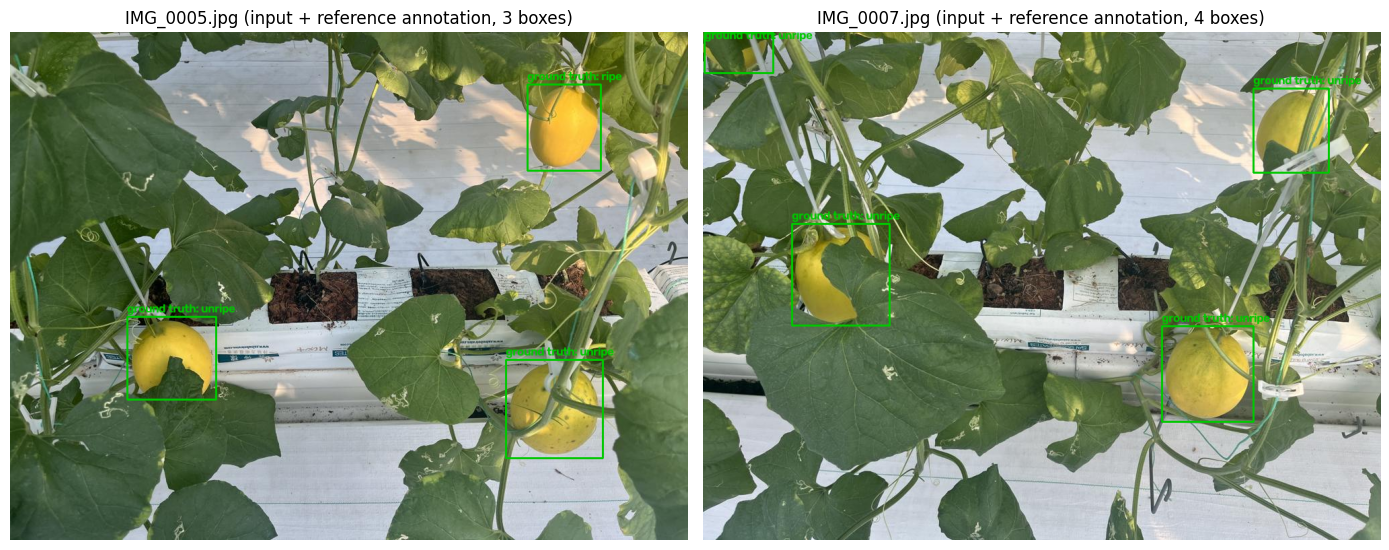

In [ ]:
import cv2
import matplotlib.pyplot as plt

def normalize_names(names):
    if isinstance(names, dict):
        return [names[k] for k in sorted(names, key=lambda x: int(x))]
    if isinstance(names, list):
        return names
    return ["class 0", "class 1"]

CLASS_NAMES = normalize_names(original_cfg.get("names"))
print("classes from melon.yaml:", CLASS_NAMES)

def load_gt_boxes(lbl_file, w, h):
    boxes = []
    for line in open(lbl_file):
        parts = line.split()
        if len(parts) >= 5:
            c, x, y, bw, bh = (float(v) for v in parts[:5])
            x, y, bw, bh = x * w, y * h, bw * w, bh * h
            boxes.append((int(c), x - bw / 2, y - bh / 2, bw, bh))
    return boxes

def draw_boxes(img, boxes, color, prefix):
    for c, x, y, bw, bh in boxes:
        p1 = (int(x), int(y))
        p2 = (int(x + bw), int(y + bh))
        cv2.rectangle(img, p1, p2, color, 2)
        cv2.putText(img, f"{prefix}: {CLASS_NAMES[c]}", (p1[0], max(p1[1] - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return img

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, name in zip(axes, ["IMG_0005.jpg", "IMG_0007.jpg"]):
    img = cv2.imread(os.path.join(img_dir, name))
    h, w = img.shape[:2]
    gt = load_gt_boxes(os.path.join(lbl_dir, name.replace(".jpg", ".txt")), w, h)
    vis = draw_boxes(img.copy(), gt, (0, 200, 0), "ground truth")
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name} (input + reference annotation, {len(gt)} boxes)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Load the released MRD.pt checkpoint (author Test.py, step 1)

Exactly as in the authors' `Test.py`: `model = YOLO('weights/MRD.pt')`. `model.info()` reports the layer count, parameters, and GFLOPs computed by the author framework at 640×640 — to be compared with the paper's 2.06 M params / 4.8 GFLOPs.

**日本語:** 著者の `Test.py` と同じく `YOLO('weights/MRD.pt')` で重みを読み込み、レイヤー数・パラメータ数・GFLOPs を表示します(論文値: 2.06 M / 4.8 G)。

In [ ]:
from ultralytics import YOLO

WEIGHTS = os.path.join(REPO_DIR, "weights", "MRD.pt")
model = YOLO(WEIGHTS)  # author Test.py step 1

info = model.info(verbose=True)  # (layers, params, gradients, GFLOPs)
n_layers, n_params, n_grads, flops_g = info
if not flops_g:
    flops_g = None  # thop unavailable/incompatible; reported as n/a instead of a false 0.0
print(f"layers: {n_layers} | params: {n_params/1e6:.3f} M | GFLOPs: {flops_g}")
print("task:", model.task)
print("classes:", model.names)

YOLOv8_CoordAtt3(2) summary: 476 layers, 2057996 parameters, 0 gradients, 4.8 GFLOPs


layers: 476 | params: 2.058 M | GFLOPs: 4.8162496
task: detect
classes: {0: 'unripe', 1: 'ripe'}


## 8. Validate on the 300-image test split (author Test.py, step 2)

`metrics = model.val(data=..., split='test', batch=1)` — the exact call from the authors' `Test.py`, on the full in-repo test split. On CPU this takes roughly 1–5 minutes for 300 images. We report both mAP@0.5 and mAP@0.5:0.95 because the paper states "mAP" without the IoU convention; its reported 97.4 % matches the mAP@0.5 magnitude.

**日本語:** 著者の `Test.py` と同一の呼び出しで、リポジトリ同梱のテスト分割 300 枚すべてを検証します(CPU で約 1〜5 分)。論文は IoU 規約を明記していないため、mAP@0.5 と mAP@0.5:0.95 の両方を報告します。

In [ ]:
metrics = model.val(data=data_yaml, split="test", batch=1)  # author Test.py, verbatim

r = metrics.results_dict
print("measured on the full 300-image test split:")
print("  precision      :", round(r["metrics/precision(B)"], 4))
print("  recall         :", round(r["metrics/recall(B)"], 4))
print("  mAP@0.5        :", round(r["metrics/mAP50(B)"], 4))
print("  mAP@0.5:0.95   :", round(r["metrics/mAP50-95(B)"], 4))
print("  per-class mAP@0.5:", dict(zip(model.names.values(),
                                        [round(x, 4) for x in metrics.box.ap50])))
print("  speed (ms/img):", {k: round(v, 1) for k, v in metrics.speed.items()})

Ultralytics YOLOv8.0.184 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon 2.20GHz)


YOLOv8_CoordAtt3(2) summary: 464 layers, 2057228 parameters, 0 gradients, 4.8 GFLOPs


  0%|          | 0.00/755k [00:00<?, ?B/s]

 85%|████████▍ | 640k/755k [00:00<00:00, 6.43MB/s]

100%|██████████| 755k/755k [00:00<00:00, 7.34MB/s]

...

                  ripe        300        329      0.969      0.953      0.987      0.931


Speed: 3.8ms preprocess, 150.4ms inference, 0.0ms loss, 0.7ms postprocess per image


FPS: 6.457


Results saved to /content/Melon-Ripeness-Detection/runs/detect/val


measured on the full 300-image test split:
  precision      : 0.958
  recall         : 0.9423
  mAP@0.5        : 0.9819
  mAP@0.5:0.95   : 0.8644
  per-class mAP@0.5: {'unripe': np.float64(0.9766), 'ripe': np.float64(0.9872)}
  speed (ms/img): {'preprocess': 3.8, 'inference': 150.4, 'loss': 0.0, 'postprocess': 0.7}


## 9. Compare with the paper's reported test-set values

The paper's comparison tables report for MRD-YOLO on the test split: P 95.0 %, R 94.1 %, mAP 97.4 %, 2.06 M params, 4.8 GFLOPs (FPS 61.74 GPU / 22.65 CPU). We tabulate paper vs. measured values. Small deviations are expected from library/torch version differences and from the paper's mAP IoU-convention ambiguity; this checks plausibility, not bit-exact equivalence.

**日本語:** 論文記載のテストセット値(P 95.0 %, R 94.1 %, mAP 97.4 %, 2.06 M, 4.8 GFLOPs)と本ノートブックの実測値を表で比較します。ライブラリバージョン差や論文の mAP 規約の曖昧さにより小さな差は許容範囲です。結果は CSV にも保存します。

In [ ]:
import pandas as pd

paper = {
    "precision": 0.950,
    "recall": 0.941,
    "mAP@0.5": 0.974,
    "params (M)": 2.06,
    "FLOPs (G)": 4.8,
}
measured = {
    "precision": r["metrics/precision(B)"],
    "recall": r["metrics/recall(B)"],
    "mAP@0.5": r["metrics/mAP50(B)"],
    "params (M)": n_params / 1e6,
    "FLOPs (G)": flops_g if flops_g is not None else float("nan"),
}
comparison = pd.DataFrame(
    {"paper (Plant Methods 2024)": paper, "this notebook (measured)": measured}
)
comparison["abs. difference"] = (comparison.iloc[:, 0] - comparison.iloc[:, 1]).abs()
if flops_g is None:
    print("GFLOPs could not be computed on this runtime (thop incompatible); shown as n/a.")
display(comparison.round(4))

csv_path = "/content/mrd_yolo_test_metrics.csv"
comparison.round(6).to_csv(csv_path)
print("saved:", csv_path)

,paper (Plant Methods 2024),this notebook (measured),abs. difference
precision,0.950,0.9580,0.0080
recall,0.941,0.9423,0.0013
mAP@0.5,0.974,0.9819,0.0079
params (M),2.060,2.0580,0.0020
FLOPs (G),4.800,4.8162,0.0162


saved: /content/mrd_yolo_test_metrics.csv


## 10. Qualitative detection — model prediction vs. reference annotation

Finally we run the model on one test image (`IMG_0005.jpg`) exactly as inference would be used in practice, and put the **model prediction (orange)** next to the **authors' reference annotation (green)** on the same input. This is a visual sanity check of the validated weights, not an additional accuracy claim.

**日本語:** 最後に、実運用と同じ推論を 1 枚のテスト画像(`IMG_0005.jpg`)に実行し、モデル予測(オレンジ)と著者の正解アノテーション(緑)を並べて表示します。これは検証済み重みの視覚的な整合確認であり、追加の精度主張ではありません。

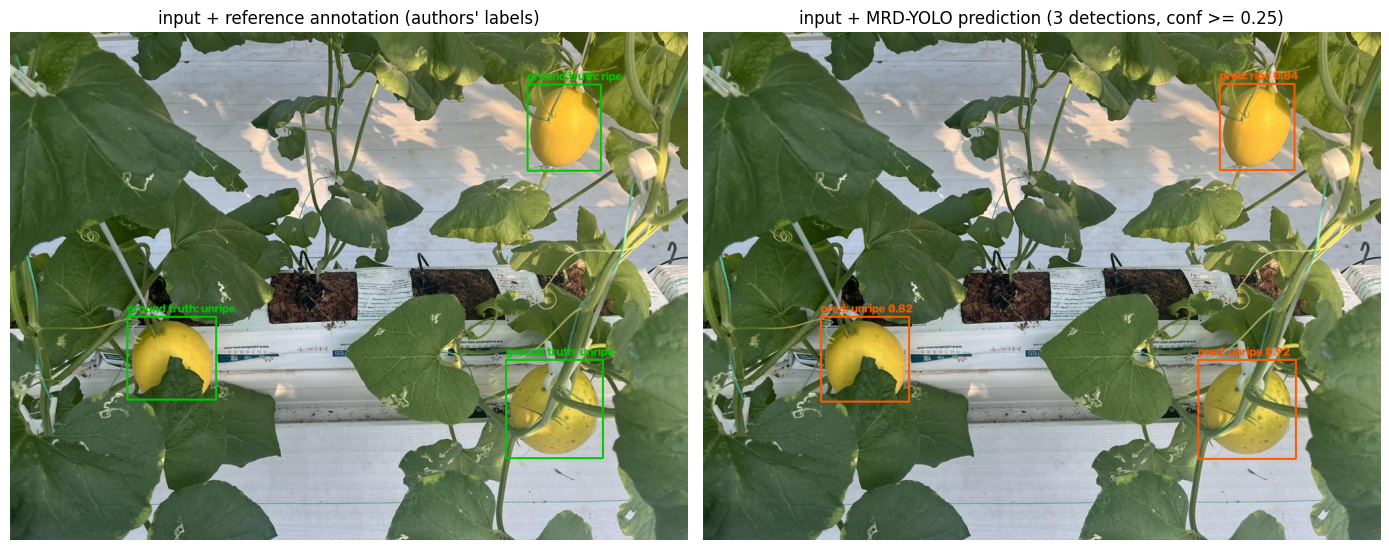

3 detections on IMG_0005.jpg


In [ ]:
SAMPLE = os.path.join(img_dir, "IMG_0005.jpg")
pred = model.predict(SAMPLE, conf=0.25, verbose=False)[0]

rows = pred.boxes.data.tolist()  # x1, y1, x2, y2, conf, cls
img = cv2.imread(SAMPLE)
img_pred = img.copy()
for x1, y1, x2, y2, conf, cls in rows:
    p1, p2 = (int(x1), int(y1)), (int(x2), int(y2))
    cv2.rectangle(img_pred, p1, p2, (0, 90, 255), 2)
    cv2.putText(img_pred, f"pred: {CLASS_NAMES[int(cls)]} {conf:.2f}",
                (p1[0], max(p1[1] - 6, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 90, 255), 2)

h, w = img.shape[:2]
gt = load_gt_boxes(os.path.join(lbl_dir, "IMG_0005.txt"), w, h)
img_gt = draw_boxes(img.copy(), gt, (0, 200, 0), "ground truth")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(cv2.cvtColor(img_gt, cv2.COLOR_BGR2RGB))
axes[0].set_title("input + reference annotation (authors' labels)")
axes[1].imshow(cv2.cvtColor(img_pred, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"input + MRD-YOLO prediction ({len(rows)} detections, conf >= 0.25)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/mrd_yolo_pred_vs_gt.png", dpi=100, bbox_inches="tight")
plt.show()
print(f"{len(rows)} detections on {os.path.basename(SAMPLE)}")

## Interpretation, limitations, references

**What was verified here:** the authors' released `weights/MRD.pt` loaded through their vendored ultralytics 8.0.184 and produced precision/recall/mAP/params/FLOPs on the repository's own 300-image test split, using the authors' exact `Test.py` procedure. Check the measured table against the paper's 95.0 / 94.1 / 97.4 (mAP@0.5), 2.06 M / 4.8 G.

**Known limitations**
- The paper states "mAP" without the IoU convention; comparison is made against mAP@0.5, and mAP@0.5:0.95 is reported alongside.
- Library versions on this VM (torch ≥ 2.6 with the documented `weights_only` shim) differ from the authors' environment (Python 3.8.16, torch 1.10.1, CUDA 11.1); small metric deltas are expected.
- The full 3806-image train/val dataset is distributed only via Baidu netdisk and is out of scope; the Roboflow generalization study is out of scope. This single-split evaluation does not verify all paper results.
- The repository has no LICENSE file; code and weights © the authors (paper: CC BY-NC-ND).

**References**
1. Jing, X. et al. Plant Methods 2024;20:127. https://doi.org/10.1186/s13007-024-01259-3 (full text via Europe PMC, PMC11328389)
2. Author code: https://github.com/XuebinJing/Melon-Ripeness-Detection @ `d8ae609f9a1e86be6402041b3770e856745e421d` (`Test.py`, `dataset/melon.yaml`, `weights/MRD.pt`, vendored ultralytics 8.0.184)
3. Ultralytics YOLOv8 (AGPL-3.0), v8.0.184 vendored in the author repository.

**日本語まとめ:** 本ノートブックは著者公開重みを著者手順(Test.py)通りにテスト分割 300 枚で検証しました。mAP は論文の IoU 規約が明記されていないため mAP@0.5 と比較し、mAP@0.5:0.95 も併記しています。完全データセット・学習・Roboflow 汎化実験は範囲外です。